In [116]:
import yfinance as yf
import pandas as pd
from matplotlib import pyplot as plt
import numpy as np
import datetime as dt

In [117]:
def fetch_option_data(ticker):
    Ticker = yf.Ticker(ticker)
    expirations = Ticker.options
    option_data = pd.DataFrame()
    
    for expiration in expirations:
        option_chain = Ticker.option_chain(expiration)
        
        calls = option_chain.calls
        calls['opt_type'] = 'c'
        
        
        puts = option_chain.puts
        puts['opt_type'] = 'p'
        
        options = pd.concat([calls, puts])
        options['exp_dt'] = pd.to_datetime(expiration)+ pd.DateOffset(hours = 23,minutes = 59, seconds =59)
        
        option_data = pd.concat([option_data, options])
        
    option_data['days_to_expiration']= (option_data['exp_dt'] - dt.datetime.today()).dt.days +1
    return option_data

In [118]:
df_options = fetch_option_data('TSLA')
df_options = df_options.loc[df_options.impliedVolatility>0.005]

In [119]:
df_options_calls = df_options.loc[df_options.opt_type =='c']
df_summary=df_options_calls.pivot_table(index='strike', 
                                  columns='exp_dt', 
                                  values='impliedVolatility',
                                  aggfunc='mean')

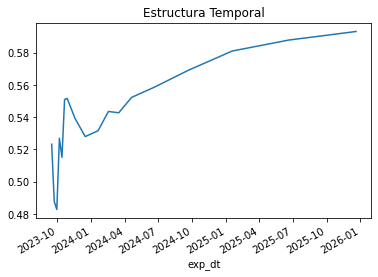

In [120]:
df_summary.loc[270].plot(title="Estructura Temporal");

In [123]:
df_summary[i].dropna()
strikes = df_summary[i].dropna().index
vols = df_summary[i].dropna().values

In [125]:
vols

array([1.58203334, 1.37988591, 1.33105803, 1.19946689, 1.08911588,
       1.06482401, 1.02441894, 0.98474136, 0.95361375, 0.93054269,
       0.8823254 , 0.84533846, 0.81472964, 0.58282888, 0.7892172 ,
       0.77386701, 0.76275872, 0.75232181, 0.74447887, 0.73477438,
       0.7256192 , 0.71527384, 0.70938401, 0.69969478, 0.69440003,
       0.68585519, 0.68133864, 0.67480794, 0.66882655, 0.66383698,
       0.66002232, 0.65347637, 0.65066878, 0.64343618, 0.63914851,
       0.63522704, 0.63125979, 0.62414927, 0.61777116, 0.61207968,
       0.60651028, 0.60162752, 0.59721777, 0.5931132 , 0.58934432,
       0.58591112, 0.58250845, 0.57965508, 0.57686275, 0.57449766,
       0.57146119, 0.56998111, 0.56851628, 0.56615119, 0.56462533,
       0.56317576, 0.56152782, 0.56097851, 0.56062756, 0.55925429,
       0.55855239, 0.55804885, 0.55735459, 0.55624833, 0.55536333,
       0.55458514, 0.55429523, 0.55406635, 0.55336445, 0.55298299,
       0.55260152, 0.55189962, 0.5515563 , 0.55127402, 0.55052

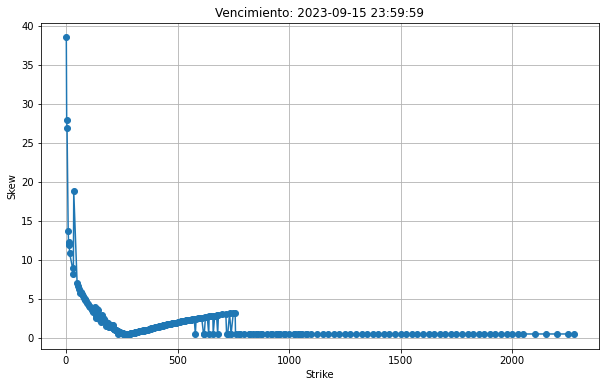

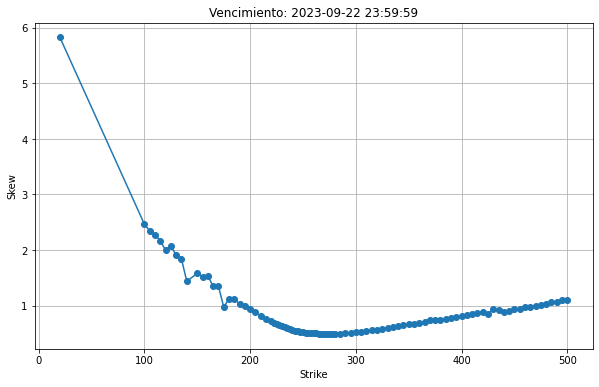

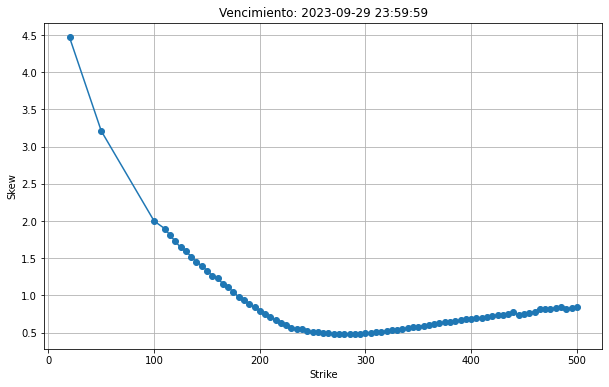

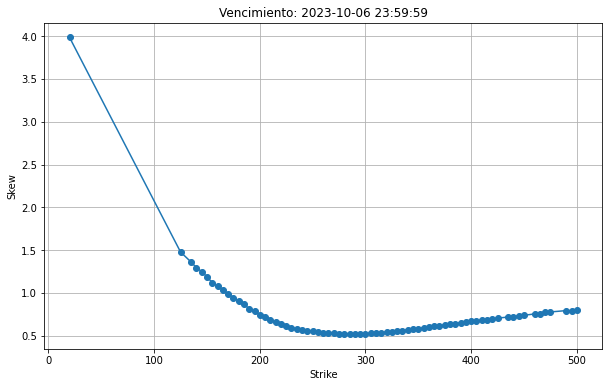

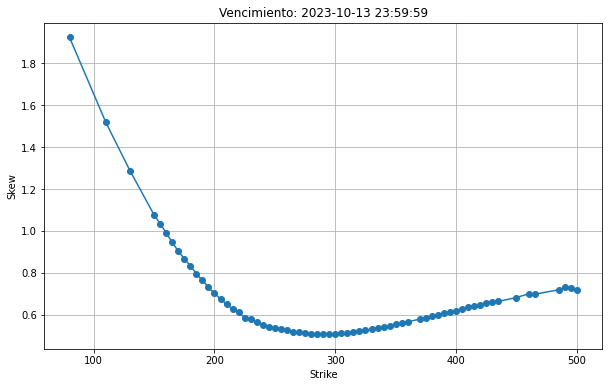

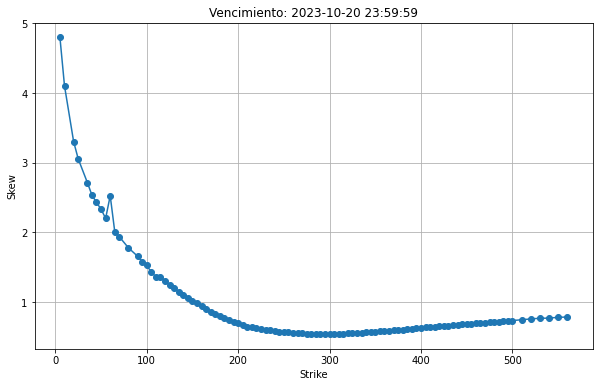

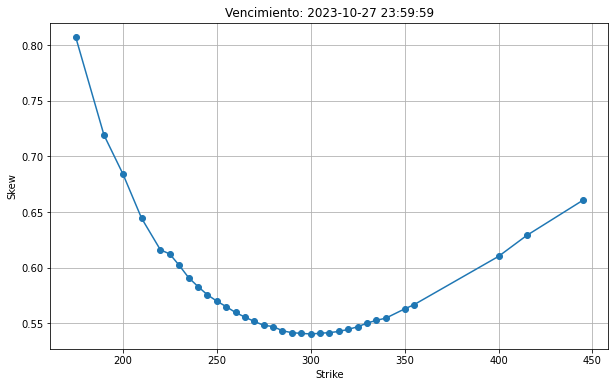

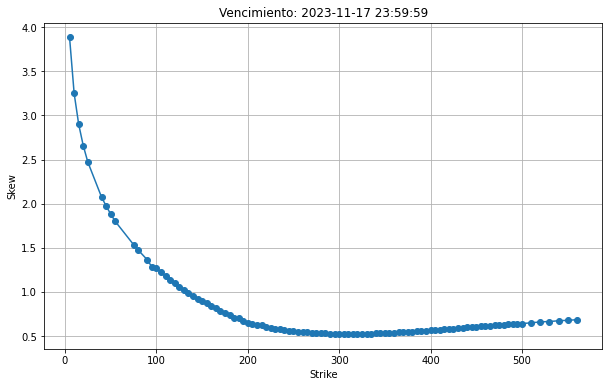

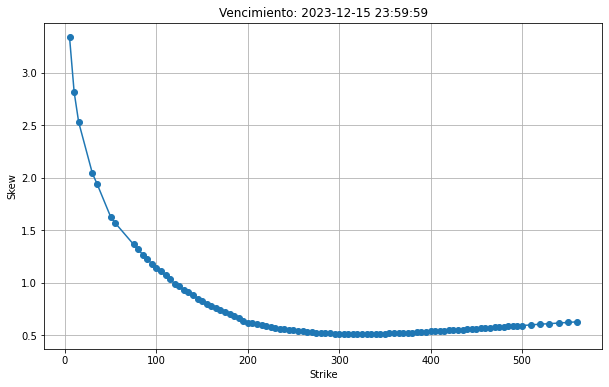

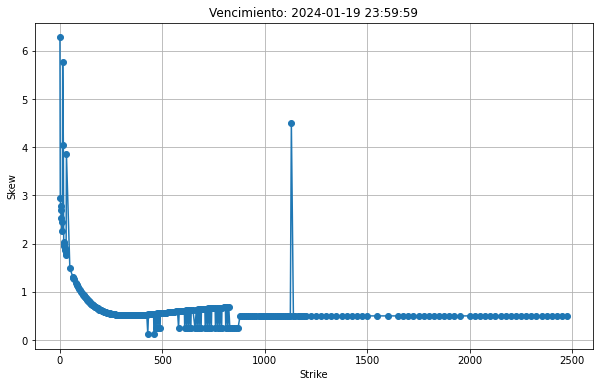

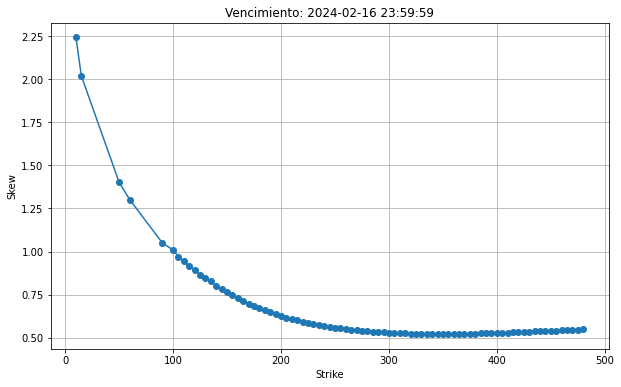

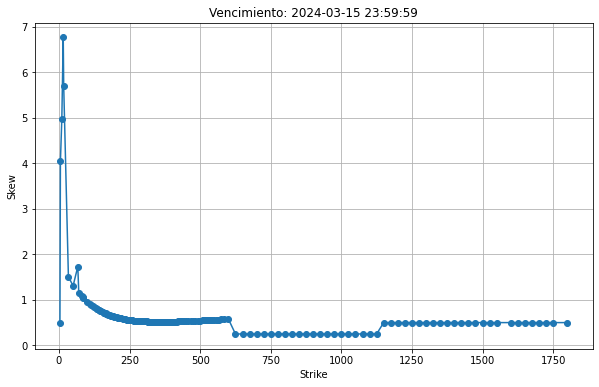

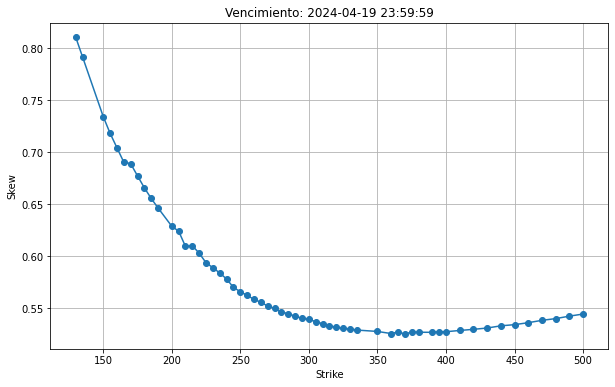

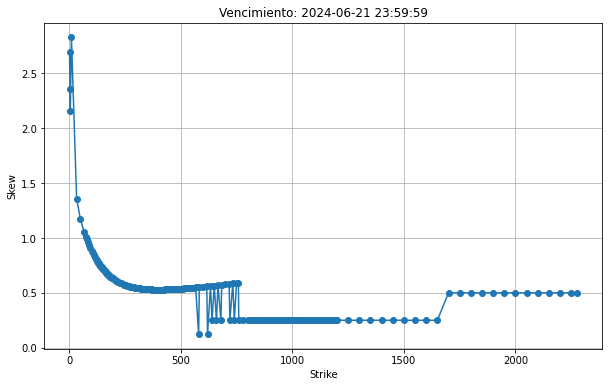

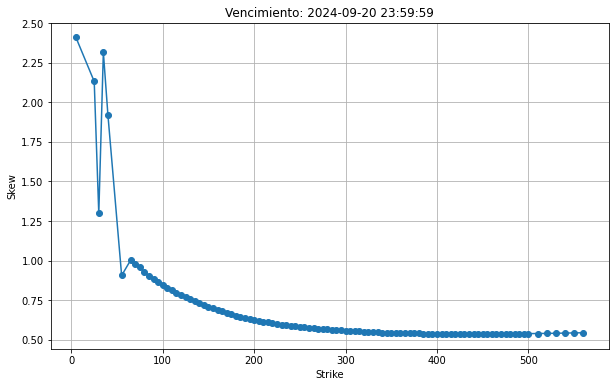

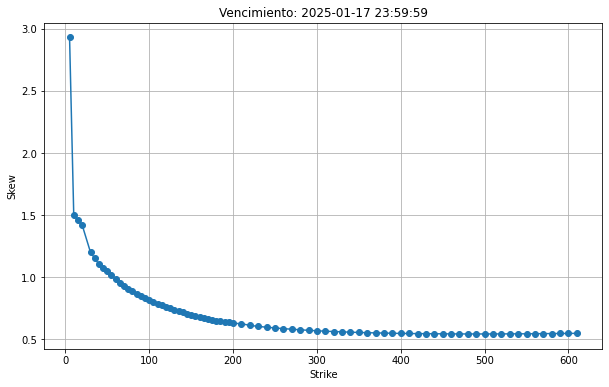

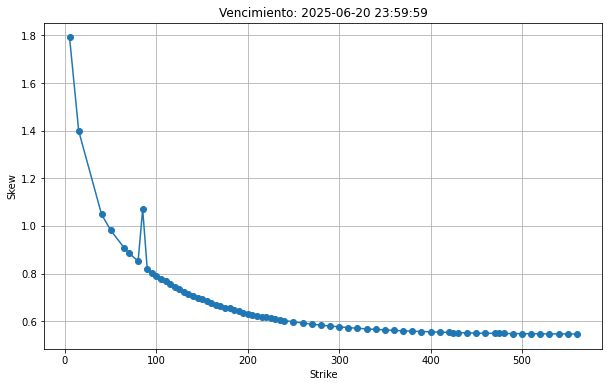

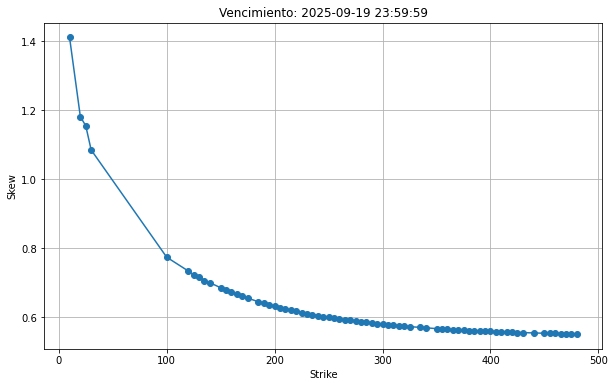

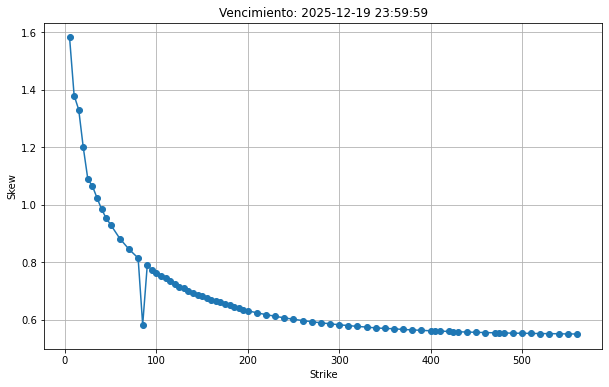

In [121]:
for i in df_summary.columns:
    plt.figure(figsize = (10,6))
    temp = df_summary[i].dropna()
    plt.plot(np.array(temp.index),temp.values,marker='o', linestyle='-')
    plt.title('Vencimiento: '+ str(i))
    plt.xlabel('Strike')
    plt.ylabel('Skew')
    plt.grid(True)
    plt.show()